# Training · snapshot DeepHit vs Dynamic-DeepHit

**加入 sensor 歷史的 dynamic model，能不能做 failure early warning？比只看「現在」的模型好多少？**

| 模型 | 輸入 |
|---|---|
| **Snapshot DeepHit** | 事故歷史 + **最新一個** 5 分鐘窗 |
| **Dynamic-DeepHit, L = 1** | 同上（同一個網路，只給 1 個窗）|
| **Dynamic-DeepHit, L = 12** | 事故歷史 + 過去 12 個窗（約 1 小時）|
| **Dynamic-DeepHit, L = 64** | 事故歷史 + 過去 64 個窗（約 7 小時）|

L = 1 / 12 / 64 用同一個網路、同一組超參數，輸入歷史長度不同；L=1 不使用 RNN、attention 與 auxiliary loss

輸出：未來 7 天內下一次觀察到的 failure 發生時間與類型。

In [1]:
import os
import json
import warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchtuples as tt
from pycox.models import DeepHit
from pycox.models.loss import DeepHitLoss
from pycox.evaluation import EvalSurv
from lifelines import AalenJohansenFitter

warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
pd.set_option("display.width", 200)

BASE_DIR = os.path.abspath("..")
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
# 每次執行都存到新的 results/<日期時間>/，不覆蓋之前的結果
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_DIR = os.path.join(BASE_DIR, "results", RUN_ID)
os.makedirs(OUT_DIR, exist_ok=False)
print("結果會存在：", OUT_DIR)

CAUSES = {1: "low", 2: "high", 3: "leak"}
FAULT_COLORS = {"low": "#2a78d6", "high": "#eb6834", "leak": "#1baf7a"}
EDGES_H = np.array([0, 0.5, 1, 2, 4, 6, 9, 12, 18, 24, 36, 48, 72, 96, 120, 144, 168])   # 跟 02 一樣
NUM_DURATIONS = len(EDGES_H) - 1
HORIZON_H = 168

結果會存在： results/20261011_145955


In [ ]:
# ----- 實驗設定 -----
SEED = 7299
LOOKBACKS = [1, 12, 64]            # Dynamic-DeepHit 的歷史長度（窗數）
CLIP = 10                          # 標準化後的值截在 ±10

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("device：", DEVICE)

# ----- Snapshot DeepHit -----
# （超參數在 validation 上選定：hidden {256/128, 64/32} x dropout {0.1, 0.3} x alpha {0.35, 0.7, 1.0}）
SNAP_HIDDEN = (64, 32)
SNAP_NODES = 32
SNAP_DROPOUT = 0.3
SNAP_ALPHA = 1.0                   # NLL 的權重（1 - alpha 給 ranking loss）
SNAP_EPOCHS = 100
SNAP_PATIENCE = 10

# ----- Dynamic-DeepHit -----
# 結構照論文（chl8856/Dynamic-DeepHit）；訓練超參數在 validation 上用 val NLL 選定（L = 64）：
#   1. (RNN hidden, FC hidden) {32, 100}² × lr {1e-3, 1e-4} × dropout {0.1, 0.3}，gamma 固定 0.1
#   2. 固定上一步的設定，gamma {0, 0.1, 1}
DDH_RNN_TYPE = "LSTM"
DDH_LAYERS_RNN = 2
DDH_H_RNN = 32                     # RNN hidden
DDH_H_FC = 100                     # FC hidden
DDH_LR = 1e-4
DDH_DROPOUT = 0.1
DDH_GAMMA = 1.0                    # RNN 預測 loss 的權重
DDH_ALPHA = 1.0                    # NLL
DDH_BETA = 0.1                     # ranking loss（不設成 0）
DDH_REG_W = 1e-5                   # cause-specific 層的 L1
DDH_BATCH = 512
DDH_BURN_IN_EPOCHS = 1             # 先只用 RNN 預測 loss 訓練的 epoch 數（gamma = 0 時跳過）
DDH_EPOCHS = 40
DDH_PATIENCE = 5

# ----- 共用 -----
SIGMA = 0.1
LR = 1e-3
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 512                   # snapshot 用

device： mps


## 1. 讀資料

In [3]:
windows = pd.read_parquet(os.path.join(PROCESSED_DIR, "windows.parquet"))
lm = pd.read_parquet(os.path.join(PROCESSED_DIR, "landmarks.parquet"))
ep = pd.read_parquet(os.path.join(PROCESSED_DIR, "episodes.parquet"))
lm = lm.merge(ep[["episode_id", "event"]].rename(columns={"event": "ep_event"}), on="episode_id")

C_VAL = lm.loc[lm.split == "train", "t"].max()
SEQ_COLS = [c for c in windows.columns if c not in ["tool", "episode_id", "win", "win_idx", "t_first", "t_last"]]
print(len(windows), "個窗，", len(SEQ_COLS), "個 sensor 特徵")

lm_tr = lm[(lm.split == "train") & lm["sample"]].reset_index(drop=True)
lm_va = lm[(lm.split == "val") & lm["sample"]].reset_index(drop=True)
lm_te = lm[(lm.split == "test") & lm["sample"]].reset_index(drop=True)
print("train / val / test：", len(lm_tr), len(lm_va), len(lm_te))

1295233 個窗， 52 個 sensor 特徵
train / val / test： 61460 15385 26252


## 2. 標準化

Sensor 與事故歷史特徵以 training set 統計量進行標準化。

- sensor 特徵：用 t ≤ C_VAL 的窗；筆數、run 數、間隔先取 log
- 事故歷史：前一次事故類型做 one-hot，次數和經過時間先取 log，再用 train 的預測時間點標準化

In [4]:
# sensor 特徵
seq = windows[SEQ_COLS].astype(float).copy()
for c in ["n_rows", "n_runs", "gap_s"]:
    seq[c] = np.log1p(seq[c])

is_train_win = (windows.t_last <= C_VAL).to_numpy()
seq_mean = seq[is_train_win].mean()
seq_std = seq[is_train_win].std().replace(0, 1)
SEQ = ((seq - seq_mean) / seq_std).clip(-CLIP, CLIP).to_numpy(np.float32)    # (窗數, 特徵數)

# 每個 episode 的第一個窗在 SEQ 的第幾列（windows 已依 episode、win_idx 排好）
assert (windows.groupby("episode_id").win_idx.diff().dropna() == 1).all()
first_row = pd.Series(np.arange(len(windows))).groupby(windows.episode_id.to_numpy()).min()

In [5]:
# 事故歷史
def static_features(d):
    f = pd.DataFrame(index=d.index)
    for p in ["none", "low", "high", "leak"]:
        f[f"prev_{p}"] = (d.prev_type == p).astype(float)
    for c in ["elapsed_h", "inc_7d", "inc_30d", "inc_30d_low", "inc_30d_high", "inc_30d_leak"]:
        f[c] = np.log1p(d[c].astype(float))
    return f

st_train = static_features(lm[lm.split == "train"])
st_mean, st_std = st_train.mean(), st_train.std().replace(0, 1)
STATIC_COLS = list(st_train.columns)
print(len(STATIC_COLS), "個事故歷史特徵：", STATIC_COLS)
# 各 sensor 窗當時的事故歷史：只讀取 landmark 已建立的 covariates，不讀事件標籤。
HISTORY_COLS = ["prev_type", "elapsed_h", "inc_7d", "inc_30d",
                "inc_30d_low", "inc_30d_high", "inc_30d_leak"]
history_rows = lm[["episode_id", "win_idx", "t"] + HISTORY_COLS].copy()
key_cols = ["episode_id", "win_idx"]
for c in ["t"] + HISTORY_COLS:
    assert history_rows.groupby(key_cols)[c].nunique(dropna=False).max() <= 1, f"同一窗的 {c} 不一致"
history_rows = history_rows.drop_duplicates(key_cols)
window_history = windows[key_cols + ["t_last"]].merge(
    history_rows, on=key_cols, how="left", validate="one_to_one", sort=False)
assert len(window_history) == len(windows)
assert window_history[key_cols].equals(windows[key_cols].reset_index(drop=True))
history_available = window_history[HISTORY_COLS + ["t"]].notna().all(axis=1).to_numpy()
assert (window_history.loc[history_available, "t_last"] <= window_history.loc[history_available, "t"]).all()
HISTORY_SEQ = ((static_features(window_history) - st_mean) / st_std).clip(-CLIP, CLIP).to_numpy(np.float32)


10 個事故歷史特徵： ['prev_none', 'prev_low', 'prev_high', 'prev_leak', 'elapsed_h', 'inc_7d', 'inc_30d', 'inc_30d_low', 'inc_30d_high', 'inc_30d_leak']


## 3. 組成序列

每個預測時間點 t：取所屬 episode 中 **t 以前（含）最近的 L 個窗**。episode 剛開始、不足 L 個窗的，後面補 0，另外記下實際長度。

In [6]:
def make_batch(d, L):
    """回傳 (x_seq, lengths, x_static, x_history), (time_idx, event)"""
    end = first_row.loc[d.episode_id].to_numpy() + d.win_idx.to_numpy()      # t 這個窗在 SEQ 的列
    lengths = np.minimum(d.win_idx.to_numpy() + 1, L)
    start = end - lengths + 1
    rows = start[:, None] + np.arange(L)[None, :]
    valid = np.arange(L)[None, :] < lengths[:, None]
    x_seq = SEQ[np.where(valid, rows, 0)] * valid[..., None]                 # (N, L, F)，超出長度的補 0

    x_static = ((static_features(d) - st_mean) / st_std).clip(-CLIP, CLIP).to_numpy(np.float32)
    selected_rows = rows[valid]
    if not history_available[selected_rows].all():
        missing = windows.iloc[np.unique(selected_rows[~history_available[selected_rows]])][["episode_id", "win_idx"]]
        raise ValueError("landmarks.parquet 缺少歷史窗當時的事故特徵。請在前處理輸出所有窗的歷史特徵，不能用最新值或未來值補齊。例子：\n" + missing.head().to_string(index=False))
    x_history = HISTORY_SEQ[np.where(valid, rows, 0)] * valid[..., None]
    assert np.allclose(x_history[np.arange(len(d)), lengths - 1], x_static), "最新窗與 landmark 事故特徵不一致"
    x = (x_seq.astype(np.float32), lengths.astype(np.int64), x_static, x_history)
    y = (d.time_idx.to_numpy(np.int64), d.event.to_numpy(np.int64))
    return x, y

In [7]:
# 檢查：序列裡只有 t 以前的窗
x, _ = make_batch(lm_te.iloc[:200], 64)
for i, r in lm_te.iloc[:200].iterrows():
    hist = windows[(windows.episode_id == r.episode_id) & (windows.win_idx <= r.win_idx)].tail(64)
    assert hist.t_last.max() <= r.t and len(hist) == x[1][i]
    assert np.allclose(x[0][i, :x[1][i]], SEQ[hist.index])
    assert np.allclose(x[3][i, :x[1][i]], HISTORY_SEQ[hist.index])
print("sensor 與各窗當時事故歷史檢查通過")

sensor 與各窗當時事故歷史檢查通過


## 4. 模型

**Snapshot DeepHit**：共享的 MLP → skip connection 接回原始輸入 → 每種故障一個 head，輸出 16 個時間格的機率，用 pycox 套件。

**Dynamic-DeepHit**（Lee et al., 2019）：結構照官方實作（[chl8856/Dynamic-DeepHit](https://github.com/chl8856/Dynamic-DeepHit)）用 PyTorch 改寫並微調。

```
x_j = [第 j 個窗的 sensor 特徵, 事故歷史]（各窗當時的事故歷史）
x_1 ... x_{M-1} → 2 層 LSTM → h_1 ... h_{M-1}       （最新的窗 x_M 不進 RNN）
temporal attention：e_j = FCNet([h_j, x_M])，a_j = softmax(e_j) → context = Σ a_j h_j
[x_M, context] → 共享 FC → 每種故障一個 FCNet → 一個 softmax（3 種故障 × 16 格 + 「撐過 168 小時」1 格）
loss = NLL + 0.1 × ranking + gamma × RNN 預測（有效步數平均）（h_j → N(μ_j, σ_j) 抽樣，預測 x_{j+1}）+ L1
訓練：先 burn-in（只用 RNN 預測 loss），再用全部 loss；early stopping 與超參數都用 val NLL 選
```

In [8]:
class SnapshotDeepHit(nn.Module):
    def __init__(self, n_in, hidden=SNAP_HIDDEN, nodes=SNAP_NODES, dropout=SNAP_DROPOUT):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(n_in, hidden[0]), nn.BatchNorm1d(hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.BatchNorm1d(hidden[1]), nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(hidden[1] + n_in, nodes), nn.BatchNorm1d(nodes), nn.ReLU(), nn.Dropout(dropout),
                          nn.Linear(nodes, NUM_DURATIONS))
            for _ in CAUSES
        ])

    def forward(self, x):
        z = torch.cat([x, self.shared(x)], dim=1)                       # skip connection
        return torch.stack([h(z) for h in self.heads], dim=1)          # (B, 3, 16)

In [ ]:
class DynamicDeepHit(nn.Module):
    """
    x_1 ... x_{M-1} → 多層 RNN → h_j（各層 state 接起來）
    temporal attention：e_j = FCNet([h_j, x_M])，a_j = exp(e_j) / Σ exp(e_l) → context = Σ a_j h_j
    [x_M, context] → 共享 FC → 每種故障一個 FCNet → 接起來 → 一個 softmax（3 × 16 格 + 1 格「撐過 168h」）
    RNN 預測：h_j → (μ_j, σ_j)，抽樣 z_j 預測 x_{j+1}
    """
    def __init__(self, x_dim, h_rnn, h_fc, dropout, n_rnn=DDH_LAYERS_RNN):
        super().__init__()
        n_ev = len(CAUSES)
        self.drop = nn.Dropout(dropout)
        RNN = nn.LSTM if DDH_RNN_TYPE == "LSTM" else nn.GRU
        self.rnns = nn.ModuleList([RNN(x_dim if i == 0 else h_rnn, h_rnn, batch_first=True) for i in range(n_rnn)])
        self.att = nn.Sequential(nn.Linear(n_rnn * h_rnn + x_dim, h_fc), nn.Tanh(), self.drop, nn.Linear(h_fc, 1))
        self.z_mean = nn.Linear(h_rnn, x_dim)
        self.z_std = nn.Linear(h_rnn, x_dim)
        self.shared = nn.Linear(x_dim + n_rnn * h_rnn, h_fc)
        self.cs = nn.ModuleList([
            nn.Sequential(nn.Linear(h_fc, h_fc), nn.ReLU(), self.drop, nn.Linear(h_fc, h_fc), nn.ReLU())
            for _ in range(n_ev)
        ])
        self.out = nn.Linear(n_ev * h_fc, n_ev * NUM_DURATIONS + 1)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)          # 官方用 Xavier 初始化
        self.ctx_dim = n_rnn * h_rnn
        self.aux_loss = torch.tensor(0.0)

    def forward(self, x, lengths):
        B, L, _ = x.shape
        lengths = lengths.long()
        ar = torch.arange(B, device=x.device)
        x_last = x[ar, lengths - 1]                                           # x_M：最新的窗（依實際長度）

        if L == 1:                                                            # 沒有歷史：context = 0
            context = x.new_zeros(B, self.ctx_dim)
            self.aux_loss = x.new_zeros(())
        else:
            step = torch.arange(L - 1, device=x.device)[None, :]
            hist_mask = (step < (lengths - 1)[:, None]).float()               # 1 = 有歷史的位置（x_M 不進 RNN）
            inp = x[:, :-1] * hist_mask[..., None]
            states = []
            for rnn in self.rnns:                                             # 跟官方的 DropoutWrapper 一樣：input、output 都 dropout
                h, _ = rnn(self.drop(inp))
                states.append(h)
                inp = self.drop(h)
            h_all = torch.cat(states, dim=-1)                                 # 各層 state 接起來 (B, L-1, n_rnn*h_rnn)

            e = self.att(torch.cat([h_all, x_last[:, None, :].expand(-1, L - 1, -1)], dim=-1)).squeeze(-1)
            a = torch.softmax(e.masked_fill(hist_mask == 0, -1e9), dim=1) * hist_mask   # 只有 1 個窗時全部為 0
            context = (a[..., None] * h_all).sum(1)

            # RNN 預測 loss：z_j ~ N(μ_j, σ_j) 預測 x_{j+1}，每筆有效步數與特徵取平均，再對有歷史的樣本取平均
            # （官方的 mask 多算了一格補 0 的位置，這裡只算 x_2 ... x_M）
            z = self.z_mean(inp) + torch.exp(self.z_std(inp)) * torch.randn_like(x[:, 1:])
            n_steps = hist_mask.sum(1)
            per_sample = (hist_mask * (z - x[:, 1:]).square().mean(2)).sum(1) / n_steps.clamp_min(1)
            self.aux_loss = per_sample.sum() / (n_steps > 0).sum().clamp_min(1)

        hdn = self.drop(torch.relu(self.shared(torch.cat([x_last, context], dim=1))))
        out = self.drop(torch.cat([cs(hdn) for cs in self.cs], dim=1))
        prob = torch.softmax(self.out(out), dim=1)
        return prob[:, :-1].view(B, len(CAUSES), NUM_DURATIONS)              # (B, 3, 16) 的機率質量

    def l1(self):
        """官方只在 cause-specific 層加 L1"""
        return sum(m.weight.abs().sum() for cs in self.cs for m in cs if isinstance(m, nn.Linear))


def ddh_loss(net, pmf, t, k, burn_in=False, gamma=DDH_GAMMA):
    """官方的 loss：alpha·NLL + beta·ranking + gamma·RNN 預測 + L1"""
    reg = DDH_REG_W * net.l1()
    if burn_in:
        return net.aux_loss + reg
    eps = 1e-8
    ar = torch.arange(len(t), device=t.device)
    cif = pmf.cumsum(2)                                                       # (B, 3, 16)

    # NLL：有事件 log P(T=t, K=k)；截尾 log P(T>t)（= 撐過 t 的所有格子加總）
    p_event = pmf[ar, (k - 1).clamp(min=0), t]
    p_surv = 1 - cif.sum(1)[ar, t]
    nll = -torch.where(k > 0, torch.log(p_event.clamp(eps)), torch.log(p_surv.clamp(eps))).mean()

    # ranking：i 在 t_i 發生 e、且 t_i < t_j 時，希望 F_e(t_i | i) > F_e(t_i | j)
    later = (t[:, None] < t[None, :]).float()
    eta = []
    for e in range(len(CAUSES)):
        r = cif[:, e, :][:, t].T                                              # r[i, j] = F_e(t_i | x_j)
        R = r.diagonal()[:, None] - r
        I = (k == e + 1).float()[:, None]
        eta.append((I * later * torch.exp(-R / SIGMA)).mean(1))
    rank = torch.stack(eta, 1).mean(1).mean()                                 # 對 batch 取平均（官方是加總）

    net.loss_parts = {"nll": nll.detach().item(), "rank": rank.detach().item(),
                      "aux": net.aux_loss.detach().item(), "reg": reg.detach().item(),
                      "weighted_nll": (DDH_ALPHA*nll).detach().item(),
                      "weighted_rank": (DDH_BETA*rank).detach().item(),
                      "weighted_aux": (gamma*net.aux_loss).detach().item(),
                      "tail_mean": (1-pmf.sum((1, 2))).detach().mean().item()}
    return DDH_ALPHA * nll + DDH_BETA * rank + gamma * net.aux_loss + reg

In [10]:
def fit(net, x_tr, y_tr, x_va, y_va, seed, epochs, patience, alpha):
    """Snapshot DeepHit：pycox"""
    torch.manual_seed(seed)
    np.random.seed(seed)
    opt = tt.optim.Adam(lr=LR, weight_decay=WEIGHT_DECAY)
    model = DeepHit(net, opt, alpha=alpha, sigma=SIGMA, duration_index=np.arange(NUM_DURATIONS), device=DEVICE)
    log = model.fit(x_tr, y_tr, batch_size=BATCH_SIZE, epochs=epochs, verbose=False,
                    callbacks=[tt.callbacks.EarlyStopping(patience=patience, file_path=os.path.join(OUT_DIR, "checkpoint.pt"))],
                    val_data=(x_va, y_va), val_batch_size=2048)
    return model, log.to_pandas()


def ddh_input(x):
    """事故歷史照論文放進每個時間點的 x：(N, L, 感測特徵 + 事故歷史)，補 0 的位置維持 0"""
    x_seq, lengths, x_static, x_history = x
    return np.concatenate([x_seq, x_history], axis=2).astype(np.float32), lengths


@torch.no_grad()
def ddh_predict_cif(net, x, batch_size=2048):
    """回傳 (3, 16, N) 的 CIF，格式跟 pycox 的 predict_cif 一樣"""
    net.eval()
    xs, lengths = x
    out = []
    for i in range(0, len(lengths), batch_size):
        pmf = net(torch.from_numpy(xs[i:i + batch_size]).to(DEVICE), torch.from_numpy(lengths[i:i + batch_size]).to(DEVICE))
        out.append(pmf.cumsum(2).cpu().numpy())
    return np.concatenate(out).transpose(1, 2, 0)


def ddh_val_scores(net, x_va, y_va, d_va):
    """val 的 NLL（越低越好，用來選模型）、平均 C-index、各故障 IPA@24h"""
    cif = ddh_predict_cif(net, x_va)                                          # (3, 16, N)
    pmf = np.diff(cif, axis=1, prepend=0)
    t, k = y_va
    ar = np.arange(len(t))
    p = np.where(k > 0, pmf[np.clip(k - 1, 0, None), t, ar], 1 - cif.sum(0)[t, ar])
    ev = evaluate(cif, d_va, "")
    return {"val_nll": -np.mean(np.log(np.clip(p, 1e-8, None))), "val_c_index": ev.c_index.mean(),
            **{f"val_ipa_{c}": v for c, v in zip(ev.cause, ev.ipa_24h)}}


def fit_ddh(x_tr, y_tr, x_va, y_va, d_va, h_rnn, h_fc, lr, dropout, gamma, seed):
    """先 burn-in（只用 RNN 預測 loss），再用全部 loss 訓練；每個 epoch 在 val 上算 NLL / C-index / IPA，
    保留 val NLL 最低的模型，連續 DDH_PATIENCE 個 epoch 沒進步就停"""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    xs, lengths = x_tr
    t_all, k_all = y_tr
    net = DynamicDeepHit(xs.shape[2], h_rnn, h_fc, dropout).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)

    def run_epoch(burn_in):
        net.train()
        rows = []
        for idx in np.array_split(rng.permutation(len(lengths)), len(lengths) // DDH_BATCH):
            pmf = net(torch.from_numpy(xs[idx]).to(DEVICE), torch.from_numpy(lengths[idx]).to(DEVICE))
            loss = ddh_loss(net, pmf, torch.from_numpy(t_all[idx]).to(DEVICE), torch.from_numpy(k_all[idx]).to(DEVICE),
                            burn_in, gamma=gamma)
            opt.zero_grad()
            loss.backward()
            opt.step()
            rows.append({"train_loss": loss.item(), **({} if burn_in else net.loss_parts)})
        return pd.DataFrame(rows).mean().to_dict()

    for _ in range(DDH_BURN_IN_EPOCHS if gamma > 0 and lengths.max() > 1 else 0):
        run_epoch(burn_in=True)

    best, best_state, bad, log = np.inf, None, 0, []
    for epoch in range(DDH_EPOCHS):
        log.append({"epoch": epoch, **run_epoch(burn_in=False), **ddh_val_scores(net, x_va, y_va, d_va)})
        if log[-1]["val_nll"] < best:
            best, bad = log[-1]["val_nll"], 0
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= DDH_PATIENCE:
                break
    net.load_state_dict(best_state)
    return net, pd.DataFrame(log).set_index("epoch")

## 5. 評估指標

| 指標 | 意義 |
|---|---|
| **C-index** | 排序：比較快出事的樣本，有沒有被預測成風險比較高（0.5 = 隨機） |
| **IPA@24h** | 24 小時內出事的機率準不準，相對於「每個樣本都給 train 的平均風險」的進步（> 0 = 比平均好） |

IPA 的參考模型 = Aalen-Johansen：不看任何特徵，只用 train 的整體發生率。

In [11]:
B24 = int(np.searchsorted(EDGES_H, 24)) - 1          # 「24 小時內」= 第 B24 格結束為止

def aj_cif(d):
    """不看任何特徵的平均風險：每種故障在每個時間格結束前的累積發生率，shape (3, 16)"""
    dur = np.minimum(d.residual_h.to_numpy(), HORIZON_H)
    ev = np.where(d.residual_h.to_numpy() > HORIZON_H, 0, d.event.to_numpy())
    out = np.zeros((len(CAUSES), NUM_DURATIONS))
    for k in CAUSES:
        ajf = AalenJohansenFitter(calculate_variance=False, seed=0)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ajf.fit(dur, ev, event_of_interest=k)
        cd = ajf.cumulative_density_.iloc[:, 0]
        out[k - 1] = [cd[cd.index <= t].iloc[-1] for t in EDGES_H[1:]]
    return out

def censor_km(time_idx, event):
    """G[j] = 第 j 格開始前還沒被截尾的機率（IPCW 的權重）"""
    G = np.ones(NUM_DURATIONS + 1)
    for m in range(NUM_DURATIONS):
        cens = ((event == 0) & (time_idx == m)).sum()
        at_risk = (time_idx > m).sum() + cens
        G[m + 1] = G[m] * (1 - cens / at_risk) if at_risk else G[m]
    return G

def ipcw_brier(p, time_idx, event, cause, b, G):
    """第 b 格結束前發生 cause 的機率 p 的 Brier score（截尾用 IPCW 加權）"""
    happened = (event > 0) & (time_idx <= b)                              # b 以前出事（任何類型）
    survived = ((event > 0) & (time_idx > b)) | ((event == 0) & (time_idx >= b))   # 確定撐過 b
    w = np.zeros(len(event))
    w[happened] = 1 / G[time_idx[happened]]
    w[survived] = 1 / G[b]
    y = (happened & (event == cause)).astype(float)
    return np.mean(w * (y - p) ** 2)

def evaluate(cif, d, name):
    """cif: (3, 16, N)；回傳每種故障的 C-index、IPA@24h"""
    t, e = d.time_idx.to_numpy(), d.event.to_numpy()
    G = censor_km(t, e)
    rows = []
    for k, cause in CAUSES.items():
        surv = pd.DataFrame(1 - cif[k - 1], index=np.arange(NUM_DURATIONS))
        c_index = EvalSurv(surv, t, (e == k).astype(int)).concordance_td()
        bs = ipcw_brier(cif[k - 1, B24], t, e, k, B24, G)
        bs_null = ipcw_brier(np.full(len(d), NULL_CIF[k - 1, B24]), t, e, k, B24, G)
        rows.append({"model": name, "cause": cause, "c_index": c_index, "ipa_24h": 1 - bs / bs_null})
    return pd.DataFrame(rows)

NULL_CIF = aj_cif(lm_tr)
print("train 的平均 24 小時風險：", dict(zip(CAUSES.values(), NULL_CIF[:, B24].round(3))))

train 的平均 24 小時風險： {'low': np.float64(0.061), 'high': np.float64(0.012), 'leak': np.float64(0.006)}


## 6. 訓練

In [12]:
torch.manual_seed(SEED)

results, logs = [], {}

# Snapshot DeepHit：事故歷史 + 最新一個窗
def snapshot(x):
    x_seq, lengths, x_static, _ = x
    return np.hstack([x_static, x_seq[np.arange(len(lengths)), lengths - 1]])

(x_tr, y_tr), (x_va, y_va), (x_te, _) = make_batch(lm_tr, 1), make_batch(lm_va, 1), make_batch(lm_te, 1)
name = "Snapshot DeepHit"
net = SnapshotDeepHit(len(STATIC_COLS) + len(SEQ_COLS))
model, logs[name] = fit(net, snapshot(x_tr), y_tr, snapshot(x_va), y_va, SEED, SNAP_EPOCHS, SNAP_PATIENCE, SNAP_ALPHA)
results.append(evaluate(model.predict_cif(snapshot(x_te)), lm_te, name))
torch.save(net.state_dict(), os.path.join(OUT_DIR, "snapshot_deephit.pt"))
print(f"{name}：best epoch {logs[name].val_loss.idxmin()}")

Snapshot DeepHit：best epoch 2


### Dynamic-DeepHit：超參數

使用兩階段 grid search 在 val 上用 val NLL 選定

| 步驟 | 比較 | 選定 |
|---|---|---|
| 1 | (RNN hidden, FC hidden) {32, 100}² × lr {1e-3, 1e-4} × dropout {0.1, 0.3}，gamma = 0.1 | RNN 32、FC 100、lr 1e-4、dropout 0.1 |
| 2 | gamma {0, 0.1, 1} | gamma = 1 |




In [13]:
# Dynamic-DeepHit：L = 1 / 12 / 64，同一組超參數
for L in LOOKBACKS:
    (x_tr, y_tr), (x_va, y_va), (x_te, _) = make_batch(lm_tr, L), make_batch(lm_va, L), make_batch(lm_te, L)
    x_tr, x_va, x_te = ddh_input(x_tr), ddh_input(x_va), ddh_input(x_te)
    name = f"Dynamic-DeepHit L={L}"
    net, logs[name] = fit_ddh(x_tr, y_tr, x_va, y_va, lm_va, DDH_H_RNN, DDH_H_FC, DDH_LR, DDH_DROPOUT, DDH_GAMMA, SEED)
    logs[name].to_csv(os.path.join(OUT_DIR, f"ddh_L{L}_log.csv"))
    results.append(evaluate(ddh_predict_cif(net, x_te), lm_te, name))
    torch.save(net.state_dict(), os.path.join(OUT_DIR, f"ddh_L{L}.pt"))
    print(f"{name}：best epoch {logs[name].val_nll.idxmin()}")

res = pd.concat(results, ignore_index=True)
res.to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)

hparams = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, tuple, dict))}
with open(os.path.join(OUT_DIR, "hparams.json"), "w") as f:
    json.dump({**hparams, "SEQ_COLS": SEQ_COLS, "STATIC_COLS": STATIC_COLS}, f, indent=2, default=str)

Dynamic-DeepHit L=1：best epoch 11


Dynamic-DeepHit L=12：best epoch 11


Dynamic-DeepHit L=64：best epoch 8


### 訓練曲線

- Snapshot：train / val loss
- Dynamic-DeepHit：train / val 的 NLL
- 虛線 = val loss / val NLL 最低的 epoch（保留的模型）

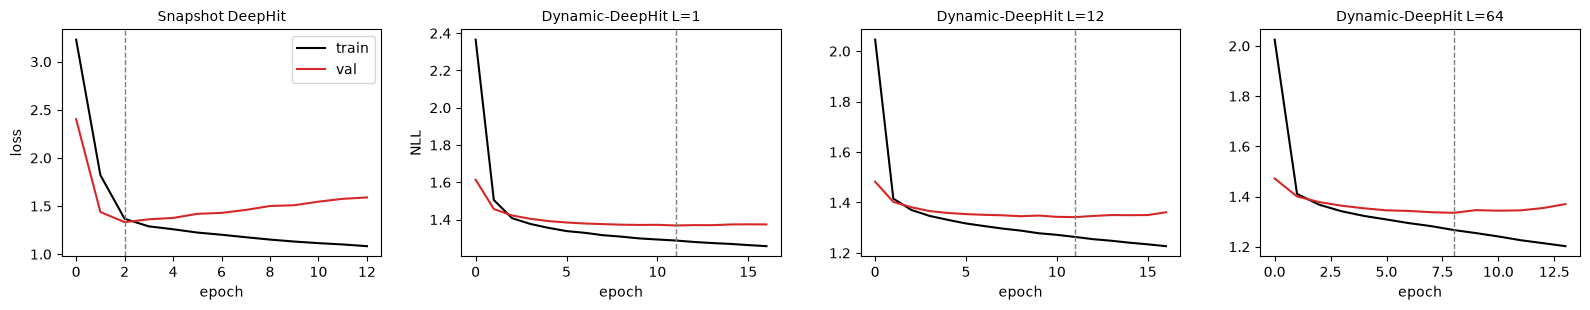

In [14]:
fig, axes = plt.subplots(1, len(logs), figsize=(4 * len(logs), 3.2))
for ax, (name, log) in zip(axes, logs.items()):
    tr, va = ("nll", "val_nll") if "val_nll" in log else ("train_loss", "val_loss")
    ax.plot(log.index, log[tr], label="train", color="black")
    ax.plot(log.index, log[va], label="val", color="tab:red")
    ax.axvline(log[va].idxmin(), color="gray", ls="--", lw=1)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[1].set_ylabel("NLL")
axes[0].legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "loss_curves.png"), dpi=150)
plt.show()

- **Snapshot DeepHit**：val loss 在第 2 個 epoch 最低，之後一路上升、train loss 繼續下降 → 很快就 overfit，early stopping 保留第 2 個 epoch。
- **Dynamic-DeepHit**：前 1～2 個 epoch 大幅下降，之後 val NLL 慢慢下降到最低點（L = 1、12 在第 11 個 epoch，L = 64 在第 8 個），再微幅上升。lr 1e-4 讓 overfit 比 snapshot 慢很多。
- **歷史越長，val NLL 越低**：1.368（L = 1）→ 1.342（L = 12）→ 1.335（L = 64）；val C-index 0.671 → 0.695 → 0.707。但 L = 64 的 val NLL 也最早回升。

## 7. 結果

test 期間（第 326 天之後）。

In [15]:
MODELS = ["Snapshot DeepHit"] + [f"Dynamic-DeepHit L={L}" for L in LOOKBACKS]
table = res.set_index(["cause", "model"]).loc[pd.MultiIndex.from_product([list(CAUSES.values()), MODELS])]
table.round(3)

c_index  ipa_24h
cause model                                 
low   Snapshot DeepHit        0.790    0.177
      Dynamic-DeepHit L=1     0.817    0.240
      Dynamic-DeepHit L=12    0.818    0.252
      Dynamic-DeepHit L=64    0.815    0.245
high  Snapshot DeepHit        0.820    0.054
      Dynamic-DeepHit L=1     0.804    0.029
      Dynamic-DeepHit L=12    0.825    0.034
      Dynamic-DeepHit L=64    0.835    0.031
leak  Snapshot DeepHit        0.567   -0.016
      Dynamic-DeepHit L=1     0.664    0.018
      Dynamic-DeepHit L=12    0.677    0.031
      Dynamic-DeepHit L=64    0.667    0.024

In [16]:
# 歷史帶來多少差異？（同一個網路，L = 12 / 64 減 L = 1）
m = res.set_index(["model", "cause"])[["c_index", "ipa_24h"]]
base = "Dynamic-DeepHit L=1"
pd.concat({f"L={L} − L=1": m.loc[f"Dynamic-DeepHit L={L}"] - m.loc[base] for L in [12, 64]}, axis=1).round(3)

L=12 − L=1         L=64 − L=1        
         c_index ipa_24h    c_index ipa_24h
cause                                      
low        0.002   0.012     -0.001   0.005
high       0.021   0.004      0.031   0.002
leak       0.013   0.012      0.003   0.006

**看到**

- **Dynamic-DeepHit 的排序在三種故障上都比 snapshot 好或相當**：壓力過低 0.790 → 0.815～0.818、壓力過高 0.820 → 0.835（L = 64）、洩漏 0.567 → 0.664～0.677。
- **機率準確度（IPA@24h）看故障類型**：壓力過低明顯提升（0.177 → 0.240～0.252）；洩漏小幅提升（−0.016 → 0.018～0.031）；**壓力過高反而變差**（0.054 → 0.029～0.034），Dynamic-DeepHit 排序比較好，但給的機率比較不準。
- **歷史長度的效果小（同一組超參數，L = 64 − L = 1）**：C-index −0.001／+0.031／+0.003，IPA +0.005／+0.002／+0.006。只有壓力過高的排序看得出進步。validation 上歷史的效果比較明顯（val C-index 0.671 → 0.707）。
- **snapshot → L = 1 的差異比 L = 1 → L = 64 大**：兩者的輸入一樣（最新一個窗 + 事故歷史），只差在網路結構和訓練方式，壓力過低的 IPA 就從 0.177 到 0.240、洩漏的 C-index 從 0.567 到 0.664 → 整體的進步大部分來自模型本身，不是來自 sensor 歷史。L = 1 也不經過 RNN、attention 和 RNN 預測 loss，所以 L = 1 和 L = 64 的差異也不全是歷史長度造成的。


## 結論

**能不能合理處理半導體設備時間序列，並搭配使用 dynamic model 做 failure early warning？**

| 問題 | 回答 |
|---|---|
| 時間序列處理 | 4 秒、只在加工時記錄的不規則資料 → 5 分鐘窗（近乎等距）+ 間隔特徵；用「有沒有恢復生產」定義事故與 episode（01、02） |
| 避免 leakage | 日曆截止日切分；每個 split 只用自己截止日以前已知的結果；窗不跨故障；標準化只用 train；序列只含 t 以前的窗，每個窗的事故歷史也只用該窗當時的值。全部有自動檢查（02；training 第 2、3 節） |
| Dynamic model | 照論文結構的 Dynamic-DeepHit（L = 64）排序在三種故障上都不比 snapshot 差（C-index +0.02～+0.10）；壓力過低的 24 小時機率準確度明顯提升（IPA 0.177 → 0.245），壓力過高則變差（0.054 → 0.031） |
| 風險從哪裡來 | **故障群聚**：輸入相同時，snapshot → L = 1 壓力過低的 IPA 就從 0.177 提升到 0.240；加入約 7 小時 sensor 歷史（L = 64）主要提升壓力過高的排序（C-index +0.031）。episode 內風險通常逐漸下降（見 interpretation），模型辨識的是「哪台機台、哪個時段危險」，而不是 sensor 的逐漸劣化 |


**限制**

- 只有約 4 成的故障發生在加工中，很多故障前一刻沒有 sensor 資料。
- 指標是對每個預測時間點平均：撐超過 7 天的 episode 只佔 19%，卻貢獻 86% 的預測時間點，所以指標主要反映平靜期的區分能力。
- 壓力過高、洩漏的 24 小時機率準確度接近 train 的平均風險（IPA ≈ 0.02～0.03）。